In [1]:
import torch

print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

!nvidia-smi

CUDA: True
GPU: Tesla T4
Tue Nov 17 21:51:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             14W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------

In [2]:
!pip install -q transformers accelerate bitsandbytes sentencepiece scikit-learn

In [3]:
import torch
import pandas as pd
import transformers
import sklearn

print("Pandas:", pd.__version__)
print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Pandas: 2.2.3
Transformers: 5.22.1
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [4]:
import os
import json
import pandas as pd
import glob

files = (
    glob.glob("/content/dataset.jsonl")
)

print("Uploaded files:")
for f in files:
    print(f)

Uploaded files:
/content/dataset.jsonl


In [5]:
DATA_PATH = "/content/dataset.jsonl"

In [8]:
import json
import pandas as pd

data = []
with open(DATA_PATH, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        line_str = line.strip()
        if not line_str:
            continue
        # Replace Python's NaN with JSON's null so json.loads doesn't crash
        line_str = line_str.replace(": NaN", ": null").replace(": nan", ": null")
        try:
            data.append(json.loads(line_str))
        except json.JSONDecodeError:
            # Safely skip truncated or corrupted lines
            continue

df = pd.DataFrame(data)

print("Total records:", len(df))
if len(df) > 0:
    print("Columns:", df.columns.tolist())

    if "Language" in df.columns:
        print("\nLanguage distribution:")
        print(df["Language"].value_counts())

    if "category" in df.columns:
        print("\nCategory distribution:")
        print(df["category"].value_counts())

    display(df.head())
else:
    print("No records could be parsed successfully.")

Total records: 36047
Columns: ['ID', 'Domain', 'Language', 'Question', 'Answer', 'category', 'unique_id', 'sentences', 'ner_tags', 'statements']

Language distribution:
Language
Marathi     7486
Gujarati    7482
Odia        7400
Hindi       7273
English     6406
Name: count, dtype: int64

Category distribution:
category
true_false_questions                9825
indian_questions                    5675
factual_questions                   4870
ner_questions                       4017
word_ordering_questions             4010
semantically_incorrect_questions    3620
chrono_questions                    2450
maths_questions                      875
reasoning_questions                  705
Name: count, dtype: int64


,ID,Domain,Language,Question,Answer,category,unique_id,sentences,ner_tags,statements
0,1,None,English,Arrange the following events in chronological ...,"Battle of Poitiers, Mexican-American War, Seco...",chrono_questions,070000000101,NaN,NaN,NaN
1,1,None,Gujarati,નીચેની ઘટનાઓને કાલક્રમિક ક્રમમાં ગોઠવો: મેક્સિ...,"પોઇટિયર્સનું યુદ્ધ, મેક્સિકન-અમેરિકન યુદ્ધ, બી...",chrono_questions,070000000103,NaN,NaN,NaN
2,1,None,Hindi,निम्नलिखित घटनाओं को कालानुक्रमिक क्रम में व्य...,"पोइटियर्स का युद्ध, मैक्सिकन-अमेरिकी युद्ध, दू...",chrono_questions,070000000102,NaN,NaN,NaN
3,1,None,Marathi,खालील घटनांची कालक्रमानुसार मांडणी करा: मेक्सि...,"पॉइटियर्सची लढाई, मेक्सिकन-अमेरिकन युद्ध, दुसर...",chrono_questions,070000000104,NaN,NaN,NaN
4,1,None,Odia,ନିମ୍ନଲିଖିତ ଘଟଣାଗୁଡ଼ିକୁ କାଳାନୁକ୍ରମିକ କ୍ରମରେ ସଜା...,"ପୋଇଟିଅର୍ସ ଯୁଦ୍ଧ, ମେକ୍ସିକାନ୍-ଆମେରିକାନ୍ ଯୁଦ୍ଧ, ଦ...",chrono_questions,070000000105,NaN,NaN,NaN


In [9]:
N_PER_GROUP = 2

sample_groups = []

for (language, category), group in df.groupby(
    ["Language", "category"]
):
    sample_groups.append(
        group.sample(
            n=min(N_PER_GROUP, len(group)),
            random_state=42
        )
    )

test_df = pd.concat(
    sample_groups,
    ignore_index=True
)

print("Selected questions:", len(test_df))

display(
    test_df.groupby(
        ["Language", "category"]
    ).size().reset_index(name="count")
)

Selected questions: 88


,Language,category,count
0,English,chrono_questions,2
1,English,factual_questions,2
2,English,indian_questions,2
3,English,maths_questions,2
4,English,reasoning_questions,2
5,English,semantically_incorrect_questions,2
6,English,true_false_questions,2
7,English,word_ordering_questions,2
8,Gujarati,chrono_questions,2
9,Gujarati,factual_questions,2


In [10]:
test_df.to_csv(
    "/content/bhram_test_sample.csv",
    index=False
)

In [11]:
import re

def evaluate_true_false(expected, prediction):

    expected = str(expected).strip().lower()
    prediction = str(prediction).strip().lower()

    if expected not in ["true", "false"]:
        return None

    # Look for an explicit answer
    prediction = re.sub(
        r"^(the answer is|answer:|final answer:)\s*",
        "",
        prediction
    )

    if prediction.startswith("true"):
        return expected == "true"

    if prediction.startswith("false"):
        return expected == "false"

    # If there is no explicit answer, leave for manual evaluation
    return None

In [12]:
import re

def extract_numbers(text):

    text = str(text)

    numbers = re.findall(
        r"-?\d+(?:\.\d+)?",
        text
    )

    if len(numbers) == 0:
        return None

    return float(numbers[-1])


def evaluate_math(expected, prediction):

    expected_num = extract_numbers(expected)
    predicted_num = extract_numbers(prediction)

    if expected_num is None or predicted_num is None:
        return None

    return expected_num == predicted_num

In [13]:
# Filter True/False questions
tf_df = df[
    df["category"].astype(str).str.strip().str.lower()
    == "true_false_questions"
].copy()

# Use Answer as the expected label
tf_df["expected_label"] = (
    tf_df["Answer"]
    .astype(str)
    .str.strip()
    .str.upper()
)

print("Total True/False questions:", len(tf_df))

print("\nExpected distribution:")
print(tf_df["expected_label"].value_counts())

print("\nLanguage distribution:")
print(tf_df["Language"].value_counts())

Total True/False questions: 9825

Expected distribution:
expected_label
TRUE     4930
FALSE    4895
Name: count, dtype: int64

Language distribution:
Language
English     1965
Gujarati    1965
Hindi       1965
Marathi     1965
Odia        1965
Name: count, dtype: int64


In [14]:
N_PER_GROUP = 20

tf_sample = (
    tf_df.groupby(
        ["Language", "expected_label"],
        group_keys=False
    )
    .sample(n=N_PER_GROUP, random_state=42)
    .reset_index(drop=True)
)

print("Selected questions:", len(tf_sample))

display(
    tf_sample.groupby(
        ["Language", "expected_label"]
    ).size().unstack(fill_value=0)
)

tf_sample.to_csv(
    "/content/TF_Balanced_200_Questions.csv",
    index=False
)

Selected questions: 200


expected_label,FALSE,TRUE
Language,,
English,20,20
Gujarati,20,20
Hindi,20,20
Marathi,20,20
Odia,20,20


In [15]:
def generate_tf_answer(model, tokenizer, question):

    messages = [
        {
            "role": "system",
            "content": (
                "You are a strict True/False classification system. "
                "Determine whether the statement is factually true or false. "
                "Respond with exactly one word: either TRUE or FALSE."
            )
        },
        {
            "role": "user",
            "content": f"Statement: {question}\n\nAnswer:"
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        # Increased max_new_tokens to 15 to prevent truncation if the model adds padding
        outputs = model.generate(
            **inputs,
            max_new_tokens=15,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return answer.strip()

In [16]:
MODELS = {
    # SLM
    "Qwen_0.5B": {
        "path": "Qwen/Qwen2.5-0.5B-Instruct",
        "type": "SLM"
    },
    "SmolLM2_1.7B": {
        "path": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
        "type": "SLM"
    },
    "TinyLlama_1.1B": {
        "path": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
        "type": "SLM"
    },

    # LLM
    "Qwen_7B": {
        "path": "Qwen/Qwen2.5-7B-Instruct",
        "type": "LLM"
    },
    "Mistral_7B": {
        "path": "mistralai/Mistral-7B-Instruct-v0.3",
        "type": "LLM"
    },
    "Zephyr_7B": {
        "path": "HuggingFaceH4/zephyr-7b-beta",
        "type": "LLM"
    }
}

In [17]:
# Check current columns
print("Current columns:", tf_sample.columns.tolist())

# Rename new dataset columns to match the existing model code
tf_sample = tf_sample.rename(columns={
    "ID": "question_id",
    "Language": "language",
    "Question": "question",
    "Answer": "expected"
})

# Normalize expected labels
tf_sample["expected"] = (
    tf_sample["expected"]
    .astype(str)
    .str.strip()
    .str.upper()
)

print("\nUpdated columns:", tf_sample.columns.tolist())

# Verify
display(
    tf_sample[
        ["question_id", "unique_id", "language",
         "category", "question", "expected"]
    ].head()
)

Current columns: ['ID', 'Domain', 'Language', 'Question', 'Answer', 'category', 'unique_id', 'sentences', 'ner_tags', 'statements', 'expected_label']

Updated columns: ['question_id', 'Domain', 'language', 'question', 'expected', 'category', 'unique_id', 'sentences', 'ner_tags', 'statements', 'expected_label']


,question_id,unique_id,language,category,question,expected
0,400,080040040001,English,true_false_questions,NaN,FALSE
1,1208,080110120801,English,true_false_questions,NaN,FALSE
2,375,080040037501,English,true_false_questions,NaN,FALSE
3,1916,080190191601,English,true_false_questions,NaN,FALSE
4,167,080020016701,English,true_false_questions,NaN,FALSE


In [18]:
required_columns = [
    "question_id",
    "unique_id",
    "language",
    "category",
    "question",
    "expected"
]

missing = [
    col for col in required_columns
    if col not in tf_sample.columns
]

if missing:
    raise ValueError("Missing columns: " + str(missing))

print("Total questions:", len(tf_sample))
print("\nLanguage distribution:")
print(tf_sample["language"].value_counts())

print("\nExpected distribution:")
print(tf_sample["expected"].value_counts())

Total questions: 200

Language distribution:
language
English     40
Gujarati    40
Hindi       40
Marathi     40
Odia        40
Name: count, dtype: int64

Expected distribution:
expected
FALSE    100
TRUE     100
Name: count, dtype: int64


In [19]:
import os
import gc
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

tf_results = []

for model_name, model_info in MODELS.items():

    print("\nProcessing:", model_name)

    model_path = model_info["path"]

    if model_info["type"] == "LLM":

        quant_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_compute_dtype=torch.float16,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True
        )

        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            quantization_config=quant_config,
            device_map="auto"
        )

    else:

        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            torch_dtype=torch.float16,
            device_map="auto"
        )

    tokenizer = AutoTokenizer.from_pretrained(model_path)

    model.eval()

    # Use the same 200 questions for every model
    for _, item in tf_sample.iterrows():

        prediction = generate_tf_answer(
            model,
            tokenizer,
            item["question"]
        )

        tf_results.append({
            "model": model_name,
            "model_type": model_info["type"],
            "question_id": item["question_id"],
            "unique_id": item["unique_id"],
            "language": item["language"],
            "category": item["category"],
            "question": item["question"],
            "expected": item["expected"],
            "prediction": prediction
        })

    # Save after each model so completed results are preserved
    os.makedirs("/content/tf_results", exist_ok=True)

    model_df = pd.DataFrame([
        x for x in tf_results
        if x["model"] == model_name
    ])

    model_df.to_csv(
        f"/content/tf_results/{model_name}.csv",
        index=False
    )

    print("Completed:", model_name)

    del model
    del tokenizer

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


tf_results_df = pd.DataFrame(tf_results)

tf_results_df.to_csv(
    "/content/TF_All_Models_Results.csv",
    index=False
)

print("\nAll six models completed!")
print("Total predictions:", len(tf_results_df))

display(tf_results_df.head())


Processing: Qwen_0.5B


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

... (62 outputs left out)

added_tokens.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/168 [00:00<?, ?B/s]

Completed: Zephyr_7B

All six models completed!
Total predictions: 1200


,model,model_type,question_id,unique_id,language,category,question,expected,prediction
0,Qwen_0.5B,SLM,400,080040040001,English,true_false_questions,NaN,FALSE,FALSE
1,Qwen_0.5B,SLM,1208,080110120801,English,true_false_questions,NaN,FALSE,FALSE
2,Qwen_0.5B,SLM,375,080040037501,English,true_false_questions,NaN,FALSE,FALSE
3,Qwen_0.5B,SLM,1916,080190191601,English,true_false_questions,NaN,FALSE,FALSE
4,Qwen_0.5B,SLM,167,080020016701,English,true_false_questions,NaN,FALSE,FALSE


In [20]:
def extract_tf(text):

    text = str(text).strip().upper()

    match = re.match(
        r"^(TRUE|FALSE)\b",
        text
    )

    if match:
        return match.group(1)

    return "INVALID"


tf_results_df["predicted_label"] = (
    tf_results_df["prediction"].apply(extract_tf)
)

tf_results_df["correct"] = (
    tf_results_df["expected"].str.upper().str.strip()
    ==
    tf_results_df["predicted_label"]
)

display(tf_results_df)

,model,model_type,question_id,unique_id,language,category,question,expected,prediction,predicted_label,correct
0,Qwen_0.5B,SLM,400,080040040001,English,true_false_questions,NaN,FALSE,FALSE,FALSE,True
1,Qwen_0.5B,SLM,1208,080110120801,English,true_false_questions,NaN,FALSE,FALSE,FALSE,True
2,Qwen_0.5B,SLM,375,080040037501,English,true_false_questions,NaN,FALSE,FALSE,FALSE,True
3,Qwen_0.5B,SLM,1916,080190191601,English,true_false_questions,NaN,FALSE,FALSE,FALSE,True
4,Qwen_0.5B,SLM,167,080020016701,English,true_false_questions,NaN,FALSE,FALSE,FALSE,True
...,...,...,...,...,...,...,...,...,...,...,...
1195,Zephyr_7B,LLM,452,080050045205,Odia,true_false_questions,NaN,TRUE,"FALSE\n\nExplanation: The statement ""nan"" is n...",FALSE,False
1196,Zephyr_7B,LLM,441,080050044105,Odia,true_false_questions,NaN,TRUE,"FALSE\n\nExplanation: The statement ""nan"" is n...",FALSE,False
1197,Zephyr_7B,LLM,793,080080079305,Odia,true_false_questions,NaN,TRUE,"FALSE\n\nExplanation: The statement ""nan"" is n...",FALSE,False
1198,Zephyr_7B,LLM,217,080030021705,Odia,true_false_questions,NaN,TRUE,"FALSE\n\nExplanation: The statement ""nan"" is n...",FALSE,False


In [21]:
tf_summary = (
    tf_results_df
    .groupby("model")
    .agg(
        Total=("correct", "count"),
        Correct=("correct", "sum")
    )
    .reset_index()
)

tf_summary["Incorrect"] = (
    tf_summary["Total"] - tf_summary["Correct"]
)

tf_summary["Accuracy (%)"] = (
    tf_summary["Correct"] / tf_summary["Total"] * 100
).round(2)

tf_summary["Error Rate (%)"] = (
    100 - tf_summary["Accuracy (%)"]
).round(2)

tf_summary = tf_summary[
    [
        "model",
        "Total",
        "Correct",
        "Incorrect",
        "Accuracy (%)",
        "Error Rate (%)"
    ]
]

display(tf_summary)

,model,Total,Correct,Incorrect,Accuracy (%),Error Rate (%)
0,Mistral_7B,200,100,100,50.0,50.0
1,Qwen_0.5B,200,100,100,50.0,50.0
2,Qwen_7B,200,100,100,50.0,50.0
3,SmolLM2_1.7B,200,100,100,50.0,50.0
4,TinyLlama_1.1B,200,0,200,0.0,100.0
5,Zephyr_7B,200,100,100,50.0,50.0


In [22]:
tf_results_df.to_csv(
    "/content/BHRAM_true_false_predictions.csv",
    index=False
)

tf_summary.to_csv(
    "/content/BHRAM_true_false_summary.csv",
    index=False
)

print("True/False results saved!")

True/False results saved!


In [23]:
false_df = df[
    df["category"] == "true_false_questions"
].copy()

print("Total True/False questions:", len(false_df))

print("\nExpected answer distribution:")
print(false_df["expected"].value_counts())

display(false_df.head(20))

Total True/False questions: 9825

Expected answer distribution:


KeyError: 'expected'

In [24]:
import pandas as pd

# Filter True/False questions
tf_df = df[
    df["category"].astype(str).str.strip().str.lower()
    == "true_false_questions"
].copy()

# Extract expected labels from Answer
tf_df["expected_label"] = (
    tf_df["Answer"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Keep only valid TRUE/FALSE records
tf_df = tf_df[
    tf_df["expected_label"].isin(["TRUE", "FALSE"])
].copy()

# Rename columns for model compatibility
tf_df = tf_df.rename(columns={
    "ID": "question_id",
    "Language": "language",
    "statements": "question",
    "Answer": "expected"
})

# Remove records without statements
tf_df = tf_df.dropna(subset=["question"])

# Select 20 questions per language per class
N_PER_GROUP = 20

tf_sample = (
    tf_df.groupby(
        ["language", "expected_label"],
        group_keys=False
    )
    .sample(n=N_PER_GROUP, random_state=42)
    .reset_index(drop=True)
)

print("Total TF records:", len(tf_df))
print("Total selected questions:", len(tf_sample))

print("\nLabel distribution:")
print(tf_sample["expected"].value_counts())

print("\nLanguage-wise distribution:")
display(
    tf_sample.groupby(
        ["language", "expected_label"]
    ).size().unstack(fill_value=0)
)

display(
    tf_sample[
        ["question_id", "unique_id", "language",
         "question", "expected"]
    ].head(10)
)

Total TF records: 9825
Total selected questions: 200

Label distribution:
expected
False    100
True     100
Name: count, dtype: int64

Language-wise distribution:


expected_label,FALSE,TRUE
language,,
English,20,20
Gujarati,20,20
Hindi,20,20
Marathi,20,20
Odia,20,20


,question_id,unique_id,language,question,expected
0,400,080040040001,English,Carbon dioxide levels have increased nearly 72...,False
1,1208,080110120801,English,"In DNA, the pyrimidines are adenine and guanin...",False
2,375,080040037501,English,The average surface pH of the ocean fell from ...,False
3,1916,080190191601,English,Mathematics uses empirical experiments to prov...,False
4,167,080020016701,English,Traditional animation involves drawing or pain...,False
5,1043,080100104301,English,George Orwell was born on 25 June 1902.,False
6,1517,080150151701,English,"The First Triumvirate was formed by Caesar, Cr...",False
7,1213,080110121301,English,"Pasteur received the Humboldt Prize of 2,500 f...",False
8,1266,080120126601,English,Sagittarius A* has a mass of 4.100 ± 0.034 bil...,False
9,359,080040035901,English,"In 2019, nearly half of the overall tree cover...",False


In [25]:
assert tf_sample["question"].notna().all()
assert (tf_sample["question"].astype(str).str.strip() != "").all()
assert tf_sample["question"].nunique() > 1

print("Missing statements:", tf_sample["question"].isna().sum())

print("\nSample statements:")
for i in range(5):
    print("\n", tf_sample.iloc[i]["language"])
    print(tf_sample.iloc[i]["question"])
    print("Expected:", tf_sample.iloc[i]["expected"])

Missing statements: 0

Sample statements:

 English
Carbon dioxide levels have increased nearly 72 % over pre-industrial levels by 2020.
Expected: False

 English
In DNA, the pyrimidines are adenine and guanine; the purines are thymine and cytosine.
Expected: False

 English
The average surface pH of the ocean fell from approximately 8.15 to 7.95 between 1950 and 2020.
Expected: False

 English
Mathematics uses empirical experiments to prove properties of objects through inductive reasoning.
Expected: False

 English
Traditional animation involves drawing or painting images by hand on transparent plastic sheets to be photographed and exhibited on film.
Expected: False


In [26]:
import torch
import pandas as pd
import gc
import os
import re

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

SYSTEM_PROMPT = """
You are a precise True/False classification system.

Determine whether the given statement is factually correct.

Rules:
1. If the statement is factually correct, answer TRUE.
2. If the statement is factually incorrect, answer FALSE.
3. Do not explain your answer.
4. Do not provide additional text.
5. Respond with exactly one word: TRUE or FALSE.
"""

models = {
    # SLM models
    "Qwen_0.5B": "Qwen/Qwen2.5-0.5B-Instruct",
    "SmolLM2_1.7B": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
    "TinyLlama_1.1B": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",

    # LLM models
    "Qwen_7B": "Qwen/Qwen2.5-7B-Instruct",
    "Mistral_7B": "mistralai/Mistral-7B-Instruct-v0.3",
    "Zephyr_7B": "HuggingFaceH4/zephyr-7b-beta"
}

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [27]:
def run_model(model_name, model_path, test_df):

    print("\nLoading model:", model_name)

    tokenizer = AutoTokenizer.from_pretrained(model_path)

    # Use 4-bit quantization for 7B models
    if "7B" in model_name:
        quant_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16
        )

        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            quantization_config=quant_config,
            device_map="auto"
        )

    else:
        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            torch_dtype=torch.float16,
            device_map="auto"
        )

    model.eval()

    predictions = []

    for i, row in test_df.iterrows():

        messages = [
            {"role": "system", "content": SYSTEM_PROMPT},
            {
                "role": "user",
                "content": "Statement: " + str(row["question"])
            }
        ]

        prompt = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        inputs = tokenizer(
            prompt,
            return_tensors="pt"
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=10,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )

        generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

        answer = tokenizer.decode(
            generated_tokens,
            skip_special_tokens=True
        ).strip()

        predictions.append({
            "model": model_name,
            "question_id": row["question_id"],
            "unique_id": row["unique_id"],
            "language": row["language"],
            "category": row["category"],
            "question": row["question"],
            "expected": row["expected"],
            "prediction": answer
        })

        if (len(predictions) % 20) == 0:
            print(
                model_name,
                "- Completed:",
                len(predictions),
                "/",
                len(test_df)
            )

    result_df = pd.DataFrame(predictions)

    # Save individual model results
    os.makedirs("/content/tf_results", exist_ok=True)

    result_df.to_csv(
        f"/content/tf_results/{model_name}.csv",
        index=False
    )

    print("Saved:", model_name)

    del model
    del tokenizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result_df

In [28]:
all_tf_results = []

for model_name, model_path in models.items():

    result_df = run_model(
        model_name,
        model_path,
        tf_sample
    )

    all_tf_results.append(result_df)

    print("Finished:", model_name)

# Combine all model predictions
tf_results_df = pd.concat(
    all_tf_results,
    ignore_index=True
)

# Save combined results
tf_results_df.to_csv(
    "/content/TF_All_Models_Results.csv",
    index=False
)

print("\nAll models completed!")
print("Total predictions:", len(tf_results_df))

display(tf_results_df.head(10))


Loading model: Qwen_0.5B


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen_0.5B - Completed: 20 / 200
Qwen_0.5B - Completed: 40 / 200
Qwen_0.5B - Completed: 60 / 200
Qwen_0.5B - Completed: 80 / 200
Qwen_0.5B - Completed: 100 / 200
Qwen_0.5B - Completed: 120 / 200
Qwen_0.5B - Completed: 140 / 200
Qwen_0.5B - Completed: 160 / 200
Qwen_0.5B - Completed: 180 / 200
Qwen_0.5B - Completed: 200 / 200
Saved: Qwen_0.5B
Finished: Qwen_0.5B

Loading model: SmolLM2_1.7B


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

SmolLM2_1.7B - Completed: 20 / 200
SmolLM2_1.7B - Completed: 40 / 200
SmolLM2_1.7B - Completed: 60 / 200
SmolLM2_1.7B - Completed: 80 / 200
SmolLM2_1.7B - Completed: 100 / 200
SmolLM2_1.7B - Completed: 120 / 200
SmolLM2_1.7B - Completed: 140 / 200
SmolLM2_1.7B - Completed: 160 / 200
SmolLM2_1.7B - Completed: 180 / 200
SmolLM2_1.7B - Completed: 200 / 200
Saved: SmolLM2_1.7B
Finished: SmolLM2_1.7B

Loading model: TinyLlama_1.1B


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (23 outputs left out)

Mistral_7B - Completed: 20 / 200
Mistral_7B - Completed: 40 / 200
Mistral_7B - Completed: 60 / 200
Mistral_7B - Completed: 80 / 200
Mistral_7B - Completed: 100 / 200
Mistral_7B - Completed: 120 / 200
Mistral_7B - Completed: 140 / 200
Mistral_7B - Completed: 160 / 200
Mistral_7B - Completed: 180 / 200
Mistral_7B - Completed: 200 / 200
Saved: Mistral_7B
Finished: Mistral_7B

Loading model: Zephyr_7B


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Zephyr_7B - Completed: 20 / 200
Zephyr_7B - Completed: 40 / 200
Zephyr_7B - Completed: 60 / 200
Zephyr_7B - Completed: 80 / 200
Zephyr_7B - Completed: 100 / 200
Zephyr_7B - Completed: 120 / 200
Zephyr_7B - Completed: 140 / 200
Zephyr_7B - Completed: 160 / 200
Zephyr_7B - Completed: 180 / 200
Zephyr_7B - Completed: 200 / 200
Saved: Zephyr_7B
Finished: Zephyr_7B

All models completed!
Total predictions: 1200


,model,question_id,unique_id,language,category,question,expected,prediction
0,Qwen_0.5B,400,080040040001,English,true_false_questions,Carbon dioxide levels have increased nearly 72...,False,TRUE
1,Qwen_0.5B,1208,080110120801,English,true_false_questions,"In DNA, the pyrimidines are adenine and guanin...",False,TRUE
2,Qwen_0.5B,375,080040037501,English,true_false_questions,The average surface pH of the ocean fell from ...,False,TRUE
3,Qwen_0.5B,1916,080190191601,English,true_false_questions,Mathematics uses empirical experiments to prov...,False,TRUE
4,Qwen_0.5B,167,080020016701,English,true_false_questions,Traditional animation involves drawing or pain...,False,TRUE
5,Qwen_0.5B,1043,080100104301,English,true_false_questions,George Orwell was born on 25 June 1902.,False,TRUE
6,Qwen_0.5B,1517,080150151701,English,true_false_questions,"The First Triumvirate was formed by Caesar, Cr...",False,FALSE
7,Qwen_0.5B,1213,080110121301,English,true_false_questions,"Pasteur received the Humboldt Prize of 2,500 f...",False,TRUE
8,Qwen_0.5B,1266,080120126601,English,true_false_questions,Sagittarius A* has a mass of 4.100 ± 0.034 bil...,False,TRUE
9,Qwen_0.5B,359,080040035901,English,true_false_questions,"In 2019, nearly half of the overall tree cover...",False,TRUE


In [29]:
from google.colab import files

files.download("/content/TF_All_Models_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
import re
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Normalize expected labels
tf_results_df["expected_label"] = (
    tf_results_df["expected"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Improved extraction that is highly robust to conversational wrapping
def extract_label(response):
    if pd.isna(response):
        return "INVALID"

    text = str(response).strip().upper()

    # First check exact output
    if text in ["TRUE", "FALSE"]:
        return text

    # Search for the last or most explicit occurrence of TRUE/FALSE in the text
    matches = re.findall(r"\b(TRUE|FALSE)\b", text)
    if matches:
        # Return the last mentioned decision (handles 'it is not TRUE, so FALSE' or conversational padding)
        return matches[-1]

    return "INVALID"


tf_results_df["predicted_label"] = (
    tf_results_df["prediction"].apply(extract_label)
)

# Correctness
tf_results_df["correct"] = (
    tf_results_df["expected_label"] ==
    tf_results_df["predicted_label"]
)

# Model-wise evaluation
results = []

for model in tf_results_df["model"].unique():

    subset = tf_results_df[
        tf_results_df["model"] == model
    ].copy()

    total = len(subset)

    invalid = (
        subset["predicted_label"] == "INVALID"
    ).sum()

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    if len(valid) > 0:

        y_true = valid["expected_label"]
        y_pred = valid["predicted_label"]

        precision = precision_score(
            y_true, y_pred,
            pos_label="TRUE",
            zero_division=0
        )

        recall = recall_score(
            y_true, y_pred,
            pos_label="TRUE",
            zero_division=0
        )

        f1 = f1_score(
            y_true, y_pred,
            pos_label="TRUE",
            zero_division=0
        )

    else:
        precision = 0
        recall = 0
        f1 = 0

    results.append({

        "Model": model,
        "Total": total,
        "Correct": int(subset["correct"].sum()),
        "Incorrect": int(
            ((~subset["correct"]) &
             (subset["predicted_label"] != "INVALID")).sum()
        ),
        "Invalid": int(invalid),

        "Accuracy (%)": round(
            subset["correct"].mean() * 100, 2
        ),

        "Valid Response (%)": round(
            (total - invalid) / total * 100, 2
        ),

        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-score (%)": round(f1 * 100, 2)
    })


metrics_df = pd.DataFrame(results)

display(metrics_df)

,Model,Total,Correct,Incorrect,Invalid,Accuracy (%),Valid Response (%),Precision (%),Recall (%),F1-score (%)
0,Qwen_0.5B,200,102,98,0,51.0,100.0,50.75,68.00,58.12
1,SmolLM2_1.7B,200,100,100,0,50.0,100.0,50.00,10.00,16.67
2,TinyLlama_1.1B,200,25,16,159,12.5,20.5,61.29,82.61,70.37
3,Qwen_7B,200,117,83,0,58.5,100.0,56.49,74.00,64.07
4,Mistral_7B,200,118,82,0,59.0,100.0,58.18,64.00,60.95
5,Zephyr_7B,200,92,85,23,46.0,88.5,58.62,18.89,28.57


In [31]:
language_results = []

for model in tf_results_df["model"].unique():

    for language in tf_results_df["language"].unique():

        subset = tf_results_df[
            (tf_results_df["model"] == model) &
            (tf_results_df["language"] == language)
        ]

        if len(subset) == 0:
            continue

        accuracy = subset["correct"].mean() * 100

        language_results.append({
            "Model": model,
            "Language": language,
            "Total": len(subset),
            "Correct": int(subset["correct"].sum()),
            "Accuracy (%)": round(accuracy, 2)
        })

language_accuracy_df = pd.DataFrame(language_results)

display(
    language_accuracy_df.pivot(
        index="Model",
        columns="Language",
        values="Accuracy (%)"
    )
)

Language,English,Gujarati,Hindi,Marathi,Odia
Model,,,,,
Mistral_7B,65.0,47.5,65.0,55.0,62.5
Qwen_0.5B,50.0,60.0,50.0,50.0,45.0
Qwen_7B,67.5,57.5,57.5,65.0,45.0
SmolLM2_1.7B,50.0,50.0,50.0,50.0,50.0
TinyLlama_1.1B,15.0,7.5,17.5,12.5,10.0
Zephyr_7B,62.5,47.5,50.0,50.0,20.0


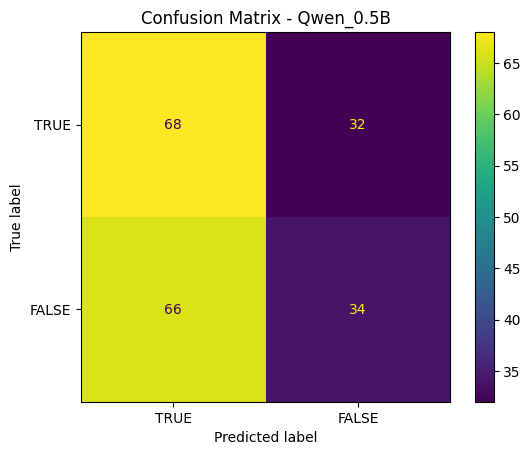

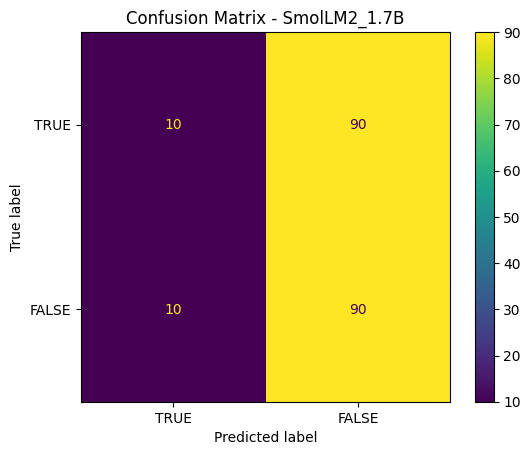

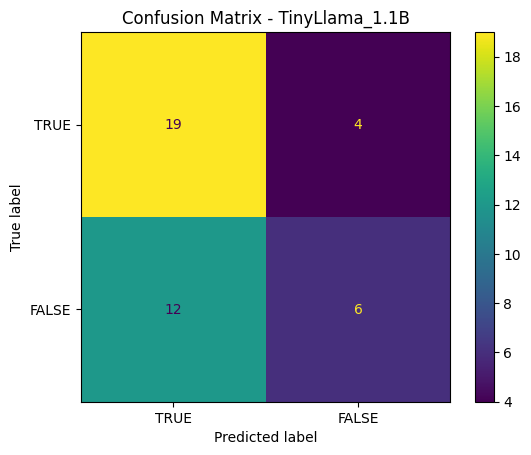

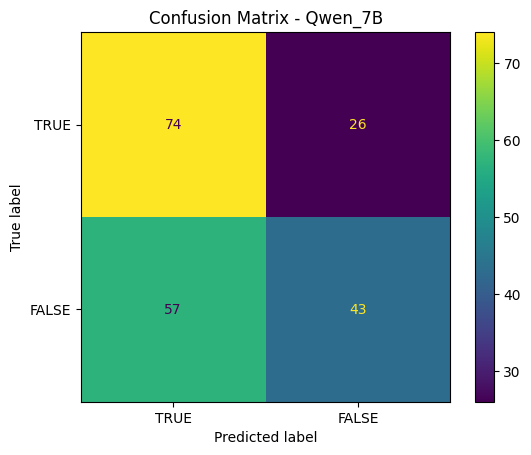

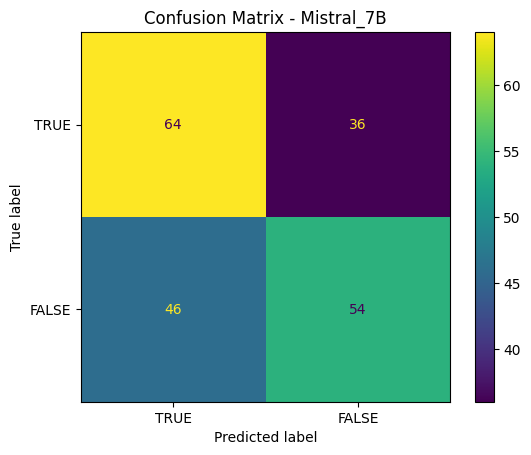

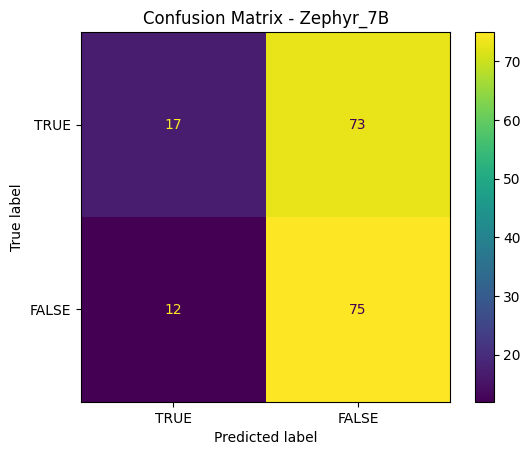

In [32]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

for model in tf_results_df["model"].unique():

    subset = tf_results_df[
        tf_results_df["model"] == model
    ]

    valid_subset = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    cm = confusion_matrix(
        valid_subset["expected_label"],
        valid_subset["predicted_label"],
        labels=["TRUE", "FALSE"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["TRUE", "FALSE"]
    )

    disp.plot()
    plt.title(f"Confusion Matrix - {model}")
    plt.show()

In [33]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Classify models into SLM and LLM
model_types = {
    "Qwen_0.5B": "SLM",
    "SmolLM2_1.7B": "SLM",
    "TinyLlama_1.1B": "SLM",
    "Qwen_7B": "LLM",
    "Mistral_7B": "LLM",
    "Zephyr_7B": "LLM"
}

tf_results_df["model_type"] = (
    tf_results_df["model"].map(model_types)
)

comparison_results = []

for model_type in ["SLM", "LLM"]:

    subset = tf_results_df[
        tf_results_df["model_type"] == model_type
    ].copy()

    total = len(subset)

    correct = int(subset["correct"].sum())

    invalid = int(
        (subset["predicted_label"] == "INVALID").sum()
    )

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    y_true = valid["expected_label"]
    y_pred = valid["predicted_label"]

    comparison_results.append({

        "Model Type": model_type,

        "Models": subset["model"].nunique(),

        "Total Predictions": total,

        "Correct": correct,

        "Incorrect": total - correct - invalid,

        "Invalid": invalid,

        "Accuracy (%)": round(
            correct / total * 100, 2
        ),

        "Valid Response (%)": round(
            len(valid) / total * 100, 2
        ),

        "Valid-only Accuracy (%)": round(
            accuracy_score(y_true, y_pred) * 100, 2
        ) if len(valid) > 0 else 0,

        "Precision (%)": round(
            precision_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) > 0 else 0,

        "Recall (%)": round(
            recall_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) > 0 else 0,

        "F1-score (%)": round(
            f1_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) > 0 else 0
    })


slm_llm_comparison = pd.DataFrame(comparison_results)

print("SLM vs LLM PERFORMANCE COMPARISON (INCLUDING ZEPHYR)")
display(slm_llm_comparison)

# Save results
slm_llm_comparison.to_csv(
    "/content/SLM_vs_LLM_Comparison.csv",
    index=False
)

SLM vs LLM PERFORMANCE COMPARISON (INCLUDING ZEPHYR)


,Model Type,Models,Total Predictions,Correct,Incorrect,Invalid,Accuracy (%),Valid Response (%),Valid-only Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,SLM,3,600,227,214,159,37.83,73.50,51.47,52.43,43.50,47.55
1,LLM,3,600,327,250,23,54.50,96.17,56.67,57.41,53.45,55.36


In [34]:

import pandas as pd
import numpy as np
import re
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# =====================================================
# 1. MODEL DETAILS AND CLASSIFICATION
# =====================================================

MODEL_DETAILS = {
    "Qwen_0.5B": {
        "Type": "SLM",
        "Model Name": "Qwen 2.5 0.5B Instruct",
        "Parameters": "0.5B",
        "HuggingFace ID": "Qwen/Qwen2.5-0.5B-Instruct"
    },
    "SmolLM2_1.7B": {
        "Type": "SLM",
        "Model Name": "SmolLM2 1.7B Instruct",
        "Parameters": "1.7B",
        "HuggingFace ID": "HuggingFaceTB/SmolLM2-1.7B-Instruct"
    },
    "TinyLlama_1.1B": {
        "Type": "SLM",
        "Model Name": "TinyLlama 1.1B Chat",
        "Parameters": "1.1B",
        "HuggingFace ID": "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
    },
    "Qwen_7B": {
        "Type": "LLM",
        "Model Name": "Qwen 2.5 7B Instruct",
        "Parameters": "7B",
        "HuggingFace ID": "Qwen/Qwen2.5-7B-Instruct"
    },
    "Mistral_7B": {
        "Type": "LLM",
        "Model Name": "Mistral 7B Instruct v0.3",
        "Parameters": "7B",
        "HuggingFace ID": "mistralai/Mistral-7B-Instruct-v0.3"
    },
    "Zephyr_7B": {
        "Type": "LLM",
        "Model Name": "Zephyr 7B Beta",
        "Parameters": "7B",
        "HuggingFace ID": "HuggingFaceH4/zephyr-7b-beta"
    }
}

# =====================================================
# 2. VALIDATE DATA AND ASSIGN MODEL TYPES
# =====================================================

required_columns = [
    "model", "language", "expected",
    "prediction", "predicted_label", "correct"
]

missing = [
    col for col in required_columns
    if col not in tf_results_df.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

tf_results_df = tf_results_df.copy()

tf_results_df["model_type"] = (
    tf_results_df["model"].map(
        {k: v["Type"] for k, v in MODEL_DETAILS.items()}
    )
)

if tf_results_df["model_type"].isna().any():
    raise ValueError("Unknown model names found in results.")

# Recalculate correctness using existing predicted_label
tf_results_df["expected_label"] = (
    tf_results_df["expected"].astype(str).str.strip().str.upper()
)

tf_results_df["predicted_label"] = (
    tf_results_df["predicted_label"].astype(str).str.strip().str.upper()
)

tf_results_df["correct"] = (
    (tf_results_df["expected_label"] ==
     tf_results_df["predicted_label"]) &
    (tf_results_df["predicted_label"].isin(["TRUE", "FALSE"]))
)

# =====================================================
# 3. INDIVIDUAL MODEL PERFORMANCE
# =====================================================

model_results = []

for model_id, info in MODEL_DETAILS.items():

    subset = tf_results_df[
        tf_results_df["model"] == model_id
    ]

    if len(subset) == 0:
        print("Warning: No predictions for", model_id)
        continue

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    y_true = valid["expected_label"]
    y_pred = valid["predicted_label"]

    total = len(subset)
    correct = int(subset["correct"].sum())
    invalid = total - len(valid)

    model_results.append({

        "Model ID": model_id,
        "Model Name": info["Model Name"],
        "Type": info["Type"],
        "Parameters": info["Parameters"],
        "HuggingFace ID": info["HuggingFace ID"],

        "Total": total,
        "Correct": correct,
        "Incorrect": total - correct - invalid,
        "Invalid": invalid,

        "Accuracy (%)": round(correct / total * 100, 2),

        "Valid Response (%)": round(
            len(valid) / total * 100, 2
        ),

        "Valid-only Accuracy (%)": round(
            accuracy_score(y_true, y_pred) * 100, 2
        ) if len(valid) else np.nan,

        "Precision (%)": round(
            precision_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else np.nan,

        "Recall (%)": round(
            recall_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else np.nan,

        "F1-score (%)": round(
            f1_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else np.nan,

        "Error Rate (%)": round(
            100 - correct / total * 100, 2
        )
    })

metrics_df = pd.DataFrame(model_results)

# =====================================================
# 4. SEPARATE SLM AND LLM TABLES
# =====================================================

slm_results = metrics_df[
    metrics_df["Type"] == "SLM"
].copy()

llm_results = metrics_df[
    metrics_df["Type"] == "LLM"
].copy()

print("\n========== SMALL LANGUAGE MODELS (SLM) ==========")
display(slm_results)

print("\n========== LARGE LANGUAGE MODELS (LLM) ==========")
display(llm_results)

print("\n========== ALL SIX MODELS ==========")
display(metrics_df)

# =====================================================
# 5. AGGREGATE SLM VS LLM COMPARISON
# =====================================================

group_results = []

for group in ["SLM", "LLM"]:

    subset = tf_results_df[
        tf_results_df["model_type"] == group
    ]

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    total = len(subset)
    correct = int(subset["correct"].sum())
    invalid = total - len(valid)

    y_true = valid["expected_label"]
    y_pred = valid["predicted_label"]

    group_results.append({

        "Model Type": group,
        "Number of Models": subset["model"].nunique(),
        "Total Predictions": total,
        "Correct": correct,
        "Incorrect": total - correct - invalid,
        "Invalid": invalid,

        "Accuracy (%)": round(
            correct / total * 100, 2
        ) if total else np.nan,

        "Valid Response (%)": round(
            len(valid) / total * 100, 2
        ) if total else np.nan,

        "Valid-only Accuracy (%)": round(
            accuracy_score(y_true, y_pred) * 100, 2
        ) if len(valid) else np.nan,

        "Precision (%)": round(
            precision_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else np.nan,

        "Recall (%)": round(
            recall_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else np.nan,

        "F1-score (%)": round(
            f1_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else np.nan,

        "Error Rate (%)": round(
            100 - correct / total * 100, 2
        ) if total else np.nan
    })

slm_llm_comparison = pd.DataFrame(group_results)

print("\n========== AGGREGATE SLM VS LLM COMPARISON ==========")
display(slm_llm_comparison)

# =====================================================
# 6. LANGUAGE-WISE ACCURACY
# =====================================================

language_performance = (
    tf_results_df
    .groupby(["model", "model_type", "language"])
    .agg(
        Total=("correct", "count"),
        Correct=("correct", "sum"),
        Invalid=(
            "predicted_label",
            lambda x: (x == "INVALID").sum()
        )
    )
    .reset_index()
)

language_performance["Accuracy (%)"] = (
    language_performance["Correct"] /
    language_performance["Total"] * 100
).round(2)

print("\n========== LANGUAGE-WISE ACCURACY ==========")
display(language_performance)

language_pivot = language_performance.pivot_table(
    index=["model", "model_type"],
    columns="language",
    values="Accuracy (%)"
)

display(language_pivot)

# =====================================================
# 7. TRUE/FALSE CLASS DISTRIBUTION
# =====================================================

class_performance = (
    tf_results_df
    .groupby(["model", "expected_label"])
    .agg(
        Total=("correct", "count"),
        Correct=("correct", "sum")
    )
    .reset_index()
)

class_performance["Accuracy (%)"] = (
    class_performance["Correct"] /
    class_performance["Total"] * 100
).round(2)

print("\n========== TRUE VS FALSE PERFORMANCE ==========")
display(class_performance)

# =====================================================
# 8. EXPORT ALL TABLES TO EXCEL
# =====================================================

output_file = "/content/BHRAM_IL_Final_Model_Comparison.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    pd.DataFrame.from_dict(
        MODEL_DETAILS, orient="index"
    ).rename_axis("Model_ID").reset_index().to_excel(
        writer, sheet_name="Model_Details", index=False
    )

    slm_results.to_excel(
        writer, sheet_name="SLM_Results", index=False
    )

    llm_results.to_excel(
        writer, sheet_name="LLM_Results", index=False
    )

    metrics_df.to_excel(
        writer, sheet_name="All_Model_Results", index=False
    )

    slm_llm_comparison.to_excel(
        writer, sheet_name="SLM_vs_LLM", index=False
    )

    language_performance.to_excel(
        writer, sheet_name="Language_Wise", index=False
    )

    language_pivot.to_excel(
        writer, sheet_name="Language_Pivot"
    )

    class_performance.to_excel(
        writer, sheet_name="True_False_Results", index=False
    )

print("\nExcel report saved:", output_file)

# =====================================================
# 9. DOWNLOAD EXCEL REPORT
# =====================================================

from google.colab import files
files.download(output_file)



========== SMALL LANGUAGE MODELS (SLM) ==========


,Model ID,Model Name,Type,Parameters,HuggingFace ID,Total,Correct,Incorrect,Invalid,Accuracy (%),Valid Response (%),Valid-only Accuracy (%),Precision (%),Recall (%),F1-score (%),Error Rate (%)
0,Qwen_0.5B,Qwen 2.5 0.5B Instruct,SLM,0.5B,Qwen/Qwen2.5-0.5B-Instruct,200,102,98,0,51.0,100.0,51.00,50.75,68.00,58.12,49.0
1,SmolLM2_1.7B,SmolLM2 1.7B Instruct,SLM,1.7B,HuggingFaceTB/SmolLM2-1.7B-Instruct,200,100,100,0,50.0,100.0,50.00,50.00,10.00,16.67,50.0
2,TinyLlama_1.1B,TinyLlama 1.1B Chat,SLM,1.1B,TinyLlama/TinyLlama-1.1B-Chat-v1.0,200,25,16,159,12.5,20.5,60.98,61.29,82.61,70.37,87.5



========== LARGE LANGUAGE MODELS (LLM) ==========


,Model ID,Model Name,Type,Parameters,HuggingFace ID,Total,Correct,Incorrect,Invalid,Accuracy (%),Valid Response (%),Valid-only Accuracy (%),Precision (%),Recall (%),F1-score (%),Error Rate (%)
3,Qwen_7B,Qwen 2.5 7B Instruct,LLM,7B,Qwen/Qwen2.5-7B-Instruct,200,117,83,0,58.5,100.0,58.50,56.49,74.00,64.07,41.5
4,Mistral_7B,Mistral 7B Instruct v0.3,LLM,7B,mistralai/Mistral-7B-Instruct-v0.3,200,118,82,0,59.0,100.0,59.00,58.18,64.00,60.95,41.0
5,Zephyr_7B,Zephyr 7B Beta,LLM,7B,HuggingFaceH4/zephyr-7b-beta,200,92,85,23,46.0,88.5,51.98,58.62,18.89,28.57,54.0



========== ALL SIX MODELS ==========


,Model ID,Model Name,Type,Parameters,HuggingFace ID,Total,Correct,Incorrect,Invalid,Accuracy (%),Valid Response (%),Valid-only Accuracy (%),Precision (%),Recall (%),F1-score (%),Error Rate (%)
0,Qwen_0.5B,Qwen 2.5 0.5B Instruct,SLM,0.5B,Qwen/Qwen2.5-0.5B-Instruct,200,102,98,0,51.0,100.0,51.00,50.75,68.00,58.12,49.0
1,SmolLM2_1.7B,SmolLM2 1.7B Instruct,SLM,1.7B,HuggingFaceTB/SmolLM2-1.7B-Instruct,200,100,100,0,50.0,100.0,50.00,50.00,10.00,16.67,50.0
2,TinyLlama_1.1B,TinyLlama 1.1B Chat,SLM,1.1B,TinyLlama/TinyLlama-1.1B-Chat-v1.0,200,25,16,159,12.5,20.5,60.98,61.29,82.61,70.37,87.5
3,Qwen_7B,Qwen 2.5 7B Instruct,LLM,7B,Qwen/Qwen2.5-7B-Instruct,200,117,83,0,58.5,100.0,58.50,56.49,74.00,64.07,41.5
4,Mistral_7B,Mistral 7B Instruct v0.3,LLM,7B,mistralai/Mistral-7B-Instruct-v0.3,200,118,82,0,59.0,100.0,59.00,58.18,64.00,60.95,41.0
5,Zephyr_7B,Zephyr 7B Beta,LLM,7B,HuggingFaceH4/zephyr-7b-beta,200,92,85,23,46.0,88.5,51.98,58.62,18.89,28.57,54.0


... (6 outputs left out)

,model,expected_label,Total,Correct,Accuracy (%)
0,Mistral_7B,FALSE,100,54,54.0
1,Mistral_7B,TRUE,100,64,64.0
2,Qwen_0.5B,FALSE,100,34,34.0
3,Qwen_0.5B,TRUE,100,68,68.0
4,Qwen_7B,FALSE,100,43,43.0
5,Qwen_7B,TRUE,100,74,74.0
6,SmolLM2_1.7B,FALSE,100,90,90.0
7,SmolLM2_1.7B,TRUE,100,10,10.0
8,TinyLlama_1.1B,FALSE,100,6,6.0
9,TinyLlama_1.1B,TRUE,100,19,19.0



Excel report saved: /content/BHRAM_IL_Final_Model_Comparison.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:

import torch
import pandas as pd
import gc
import re
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

# ==========================================
# PHI-3.5 MINI - SLM
# ==========================================

PHI_MODEL = "microsoft/Phi-3.5-mini-instruct"

phi_quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True
)

phi_tokenizer = AutoTokenizer.from_pretrained(PHI_MODEL)

phi_model = AutoModelForCausalLM.from_pretrained(
    PHI_MODEL,
    quantization_config=phi_quant_config,
    device_map="auto"
)

phi_model.eval()

phi_results = []

for i, item in tf_sample.iterrows():

    question = str(item["question"])

    messages = [
        {
            "role": "system",
            "content": (
                "You are a strict True/False classification system. "
                "Determine whether the statement is factually true or false. "
                "Respond with exactly one word: TRUE or FALSE."
            )
        },
        {
            "role": "user",
            "content": f"Statement: {question}\nAnswer:"
        }
    ]

    prompt = phi_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = phi_tokenizer(
        prompt,
        return_tensors="pt"
    ).to(phi_model.device)

    with torch.inference_mode():
        outputs = phi_model.generate(
            **inputs,
            max_new_tokens=15,
            do_sample=False,
            pad_token_id=phi_tokenizer.eos_token_id,
            use_cache=False
        )

    prediction = phi_tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    ).strip()

    phi_results.append({
        "model": "Phi_3.5_Mini",
        "model_type": "SLM",
        "question_id": item["question_id"],
        "unique_id": item["unique_id"],
        "language": item["language"],
        "category": item["category"],
        "question": question,
        "expected": item["expected"],
        "prediction": prediction
    })

    if (len(phi_results) % 20) == 0:
        print("Phi completed:", len(phi_results), "/", len(tf_sample))

phi_df = pd.DataFrame(phi_results)

phi_df.to_csv(
    "/content/Phi_3.5_Mini_40K_results.csv",
    index=False
)

print("Phi-3.5 Mini completed!")
print("Total predictions:", len(phi_df))

del phi_model
del phi_tokenizer

gc.collect()
torch.cuda.empty_cache()

display(phi_df.head())


config.json:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


tokenizer_config.json:   0%|          | 0.00/3.98k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

Phi completed: 20 / 200
Phi completed: 40 / 200
Phi completed: 60 / 200
Phi completed: 80 / 200
Phi completed: 100 / 200
Phi completed: 120 / 200
Phi completed: 140 / 200
Phi completed: 160 / 200
Phi completed: 180 / 200
Phi completed: 200 / 200
Phi-3.5 Mini completed!
Total predictions: 200


,model,model_type,question_id,unique_id,language,category,question,expected,prediction
0,Phi_3.5_Mini,SLM,400,080040040001,English,true_false_questions,Carbon dioxide levels have increased nearly 72...,False,TRUE
1,Phi_3.5_Mini,SLM,1208,080110120801,English,true_false_questions,"In DNA, the pyrimidines are adenine and guanin...",False,"FALSE\n\nExplanation: In DNA, the pyrimid"
2,Phi_3.5_Mini,SLM,375,080040037501,English,true_false_questions,The average surface pH of the ocean fell from ...,False,TRUE\n\nThe statement is factually true as it ...
3,Phi_3.5_Mini,SLM,1916,080190191601,English,true_false_questions,Mathematics uses empirical experiments to prov...,False,FALSE\n\nMathematics primarily uses deductive ...
4,Phi_3.5_Mini,SLM,167,080020016701,English,true_false_questions,Traditional animation involves drawing or pain...,False,"FALSE\n\nTraditional animation, also known as ..."


In [36]:

import pandas as pd
import numpy as np
import re

# ==========================================
# REPLACE TINYLLAMA WITH PHI-3.5 MINI
# ==========================================

# Keep the five original models
base_results = tf_results_df[
    tf_results_df["model"] != "TinyLlama_1.1B"
].copy()

# Combine with Phi results
final_results = pd.concat(
    [base_results, phi_df],
    ignore_index=True
)

# Selected six models
selected_models = [
    "Qwen_0.5B",
    "SmolLM2_1.7B",
    "Phi_3.5_Mini",
    "Qwen_7B",
    "Mistral_7B",
    "Zephyr_7B"
]

final_results = final_results[
    final_results["model"].isin(selected_models)
].copy()

# Model types
model_types = {
    "Qwen_0.5B": "SLM",
    "SmolLM2_1.7B": "SLM",
    "Phi_3.5_Mini": "SLM",
    "Qwen_7B": "LLM",
    "Mistral_7B": "LLM",
    "Zephyr_7B": "LLM"
}

final_results["model_type"] = (
    final_results["model"].map(model_types)
)

# Normalize labels
final_results["expected_label"] = (
    final_results["expected"]
    .astype(str)
    .str.strip()
    .str.upper()
)

def extract_final_label(response):

    if pd.isna(response):
        return "INVALID"

    text = str(response).strip().upper()

    if text in ["TRUE", "FALSE"]:
        return text

    matches = re.findall(r"\b(TRUE|FALSE)\b", text)

    if matches:
        return matches[-1]

    return "INVALID"

final_results["predicted_label"] = (
    final_results["prediction"].apply(extract_final_label)
)

# Invalid predictions count as incorrect
final_results["correct"] = (
    (final_results["expected_label"] ==
     final_results["predicted_label"]) &
    (final_results["predicted_label"].isin(["TRUE", "FALSE"]))
)

# ==========================================
# VALIDATION
# ==========================================

print("MODEL-WISE PREDICTION COUNTS")

display(
    final_results.groupby(
        ["model_type", "model"]
    ).size().reset_index(name="Total Predictions")
)

for model in selected_models:

    subset = final_results[
        final_results["model"] == model
    ]

    print(
        model,
        "Predictions:", len(subset),
        "Unique questions:", subset["unique_id"].nunique()
    )

    if len(subset) != 200:
        raise ValueError(
            model + " does not have exactly 200 predictions."
        )

    if set(subset["unique_id"]) != set(tf_sample["unique_id"]):
        raise ValueError(
            model + " does not have the same test questions."
        )

print("\nAll six models passed validation!")

final_results.to_csv(
    "/content/Final_6_Model_Results_40K.csv",
    index=False
)


MODEL-WISE PREDICTION COUNTS


,model_type,model,Total Predictions
0,LLM,Mistral_7B,200
1,LLM,Qwen_7B,200
2,LLM,Zephyr_7B,200
3,SLM,Phi_3.5_Mini,200
4,SLM,Qwen_0.5B,200
5,SLM,SmolLM2_1.7B,200


Qwen_0.5B Predictions: 200 Unique questions: 200
SmolLM2_1.7B Predictions: 200 Unique questions: 200
Phi_3.5_Mini Predictions: 200 Unique questions: 200
Qwen_7B Predictions: 200 Unique questions: 200
Mistral_7B Predictions: 200 Unique questions: 200
Zephyr_7B Predictions: 200 Unique questions: 200

All six models passed validation!


In [38]:

from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# ==========================================
# FINAL SLM VS LLM COMPARISON
# No dependency on model_metrics_df
# ==========================================

comparison_rows = []

for model_type in ["LLM", "SLM"]:

    group = final_results[
        final_results["model_type"] == model_type
    ].copy()

    total = len(group)
    correct = int(group["correct"].sum())

    invalid = int(
        (group["predicted_label"] == "INVALID").sum()
    )

    individual_metrics = []

    for model in group["model"].unique():

        model_data = group[
            group["model"] == model
        ]

        valid = model_data[
            model_data["predicted_label"].isin(
                ["TRUE", "FALSE"]
            )
        ]

        y_true = valid["expected_label"]
        y_pred = valid["predicted_label"]

        if len(valid) > 0:

            individual_metrics.append({
                "Balanced Accuracy": balanced_accuracy_score(
                    y_true, y_pred
                ) * 100,

                "Precision": precision_score(
                    y_true, y_pred,
                    pos_label="TRUE",
                    zero_division=0
                ) * 100,

                "Recall": recall_score(
                    y_true, y_pred,
                    pos_label="TRUE",
                    zero_division=0
                ) * 100,

                "F1": f1_score(
                    y_true, y_pred,
                    pos_label="TRUE",
                    zero_division=0
                ) * 100
            })

    metrics_df = pd.DataFrame(individual_metrics)

    comparison_rows.append({
        "Model Type": model_type,
        "Models": group["model"].nunique(),
        "Total Predictions": total,
        "Correct": correct,
        "Accuracy (%)": round(correct / total * 100, 2),
        "Avg Balanced Accuracy (%)": round(
            metrics_df["Balanced Accuracy"].mean(), 2
        ),
        "Avg Precision (%)": round(
            metrics_df["Precision"].mean(), 2
        ),
        "Avg Recall (%)": round(
            metrics_df["Recall"].mean(), 2
        ),
        "Avg F1-score (%)": round(
            metrics_df["F1"].mean(), 2
        ),
        "Invalid": invalid
    })

final_comparison_df = pd.DataFrame(comparison_rows)

print("FINAL SLM VS LLM COMPARISON - 40K DATASET")

display(final_comparison_df)

final_comparison_df.to_csv(
    "/content/Final_SLM_vs_LLM_Comparison_40K.csv",
    index=False
)

print("Comparison saved successfully!")


FINAL SLM VS LLM COMPARISON - 40K DATASET


,Model Type,Models,Total Predictions,Correct,Accuracy (%),Avg Balanced Accuracy (%),Avg Precision (%),Avg Recall (%),Avg F1-score (%),Invalid
0,LLM,3,600,327,54.50,56.68,57.76,52.3,51.20,23
1,SLM,3,600,310,51.67,51.67,51.38,47.0,44.19,0


Comparison saved successfully!


EXPERIMENT VALIDATION

Model prediction counts:


,model_type,model_name,Predictions
0,LLM,Mistral 7B,200
1,LLM,Qwen 2.5 7B,200
2,LLM,Zephyr 7B,200
3,SLM,Phi-3.5 Mini,200
4,SLM,Qwen 2.5 0.5B,200
5,SLM,SmolLM2 1.7B,200



Language distribution:


language,English,Gujarati,Hindi,Marathi,Odia
model_name,,,,,
Mistral 7B,40,40,40,40,40
Phi-3.5 Mini,40,40,40,40,40
Qwen 2.5 0.5B,40,40,40,40,40
Qwen 2.5 7B,40,40,40,40,40
SmolLM2 1.7B,40,40,40,40,40
Zephyr 7B,40,40,40,40,40



Validation completed.

INDIVIDUAL PERFORMANCE - ALL SIX MODELS


,Model,Type,Total,Correct,Incorrect,Invalid,Accuracy (%),Balanced Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,Qwen 2.5 0.5B,SLM,200,102,98,0,51.0,51.00,50.75,68.00,58.12
1,SmolLM2 1.7B,SLM,200,100,100,0,50.0,50.00,50.00,10.00,16.67
2,Phi-3.5 Mini,SLM,200,108,92,0,54.0,54.00,53.39,63.00,57.80
3,Qwen 2.5 7B,LLM,200,117,83,0,58.5,58.50,56.49,74.00,64.07
4,Mistral 7B,LLM,200,118,82,0,59.0,59.00,58.18,64.00,60.95
5,Zephyr 7B,LLM,200,92,108,23,46.0,52.55,58.62,18.89,28.57



LANGUAGE-WISE ACCURACY - SIX MODELS


Language            English  Gujarati  Hindi  Marathi  Odia
Type Model                                                 
LLM  Mistral 7B        65.0      47.5   65.0     55.0  62.5
     Qwen 2.5 7B       67.5      57.5   57.5     65.0  45.0
     Zephyr 7B         62.5      47.5   50.0     50.0  20.0
SLM  Phi-3.5 Mini      70.0      52.5   55.0     47.5  45.0
     Qwen 2.5 0.5B     50.0      60.0   50.0     50.0  45.0
     SmolLM2 1.7B      50.0      50.0   50.0     50.0  50.0


LANGUAGE-WISE AVERAGE ACCURACY - SLM VS LLM


Language,English,Gujarati,Hindi,Marathi,Odia
Type,,,,,
LLM,65.00,50.83,57.50,56.67,42.50
SLM,56.67,54.17,51.67,49.17,46.67


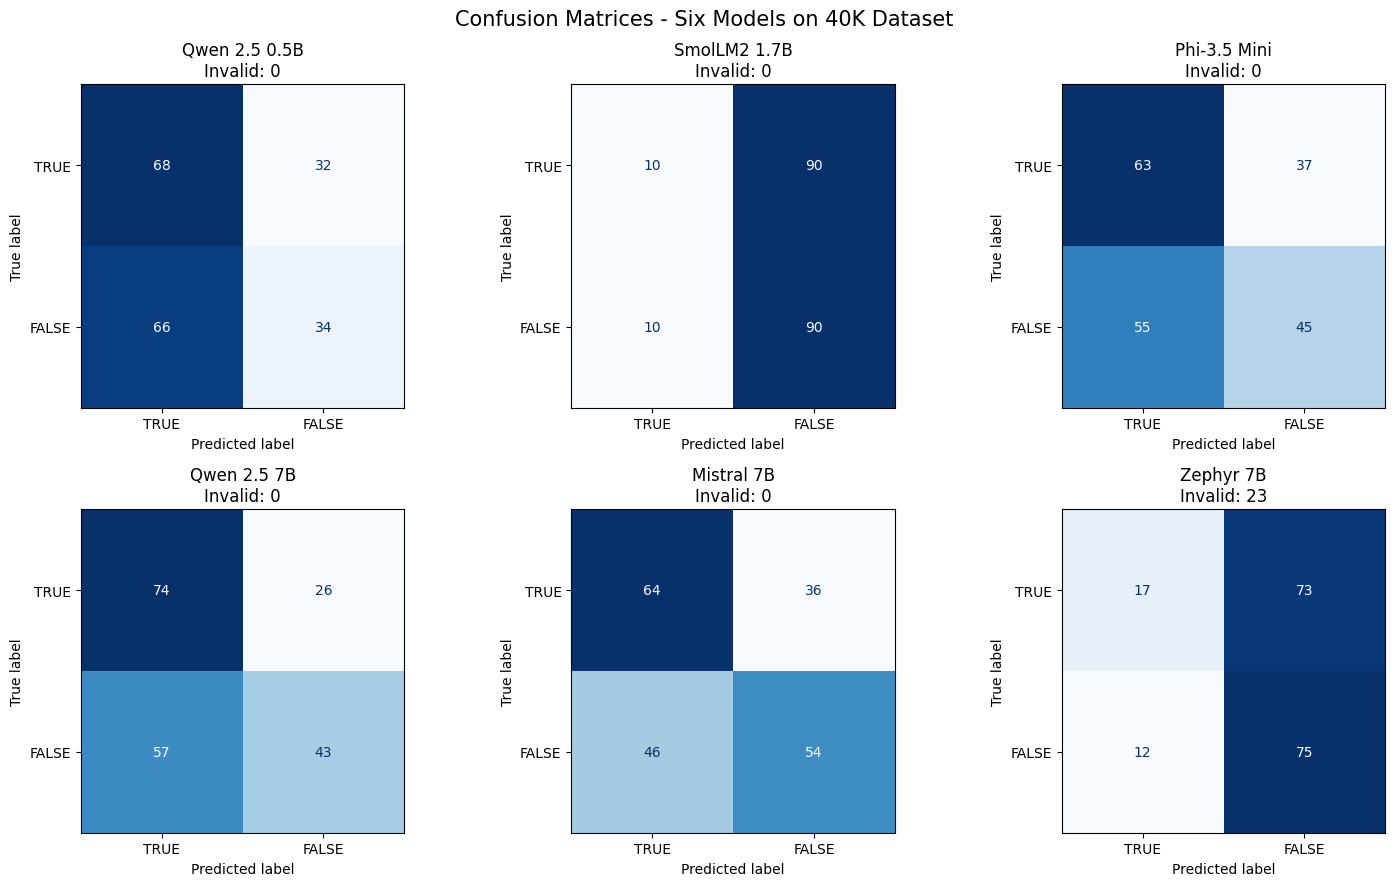


FINAL SLM VS LLM COMPARISON
AVERAGE OF THREE MODELS IN EACH GROUP


,Model Type,Number of Models,Total Predictions,Correct Predictions,Average Accuracy (%),Average Balanced Accuracy (%),Average Precision (%),Average Recall (%),Average F1-score (%),Total Invalid Predictions
0,LLM,3,600,327,54.50,56.68,57.76,52.3,51.2,23
1,SLM,3,600,310,51.67,51.67,51.38,47.0,44.2,0



All six-model comparison files saved successfully!


In [39]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# =========================================================
# 1. SELECT SIX MODELS AND REPLACE TINYLLAMA WITH PHI
# =========================================================

MODEL_DETAILS = {
    "Qwen_0.5B": {
        "Type": "SLM",
        "Name": "Qwen 2.5 0.5B"
    },
    "SmolLM2_1.7B": {
        "Type": "SLM",
        "Name": "SmolLM2 1.7B"
    },
    "Phi_3.5_Mini": {
        "Type": "SLM",
        "Name": "Phi-3.5 Mini"
    },
    "Qwen_7B": {
        "Type": "LLM",
        "Name": "Qwen 2.5 7B"
    },
    "Mistral_7B": {
        "Type": "LLM",
        "Name": "Mistral 7B"
    },
    "Zephyr_7B": {
        "Type": "LLM",
        "Name": "Zephyr 7B"
    }
}

selected_models = list(MODEL_DETAILS.keys())

# Remove TinyLlama from the original results
base_df = tf_results_df[
    tf_results_df["model"] != "TinyLlama_1.1B"
].copy()

# Add Phi results
# phi_df must contain the 200 Phi-3.5 Mini predictions
final_results = pd.concat(
    [base_df, phi_df],
    ignore_index=True
)

# Keep only the six selected models
final_results = final_results[
    final_results["model"].isin(selected_models)
].copy()

# Assign model types
final_results["model_type"] = (
    final_results["model"].map(
        {m: v["Type"] for m, v in MODEL_DETAILS.items()}
    )
)

final_results["model_name"] = (
    final_results["model"].map(
        {m: v["Name"] for m, v in MODEL_DETAILS.items()}
    )
)

# =========================================================
# 2. NORMALIZE EXPECTED AND PREDICTED LABELS
# =========================================================

final_results["expected_label"] = (
    final_results["expected"]
    .astype(str)
    .str.strip()
    .str.upper()
)

def extract_label(text):

    if pd.isna(text):
        return "INVALID"

    text = str(text).strip().upper()

    if text in ["TRUE", "FALSE"]:
        return text

    matches = re.findall(r"\b(TRUE|FALSE)\b", text)

    if matches:
        return matches[-1]

    return "INVALID"


final_results["predicted_label"] = (
    final_results["prediction"].apply(extract_label)
)

# Invalid predictions count as incorrect
final_results["correct"] = (
    (final_results["expected_label"] ==
     final_results["predicted_label"]) &
    (final_results["predicted_label"].isin(["TRUE", "FALSE"]))
)

# Normalize language names
final_results["language"] = (
    final_results["language"]
    .astype(str)
    .str.strip()
    .str.title()
)

# =========================================================
# 3. VALIDATE SIX MODELS AND FIVE LANGUAGES
# =========================================================

print("=" * 65)
print("EXPERIMENT VALIDATION")
print("=" * 65)

print("\nModel prediction counts:")

display(
    final_results.groupby(["model_type", "model_name"])
    .size()
    .reset_index(name="Predictions")
)

print("\nLanguage distribution:")

display(
    final_results.groupby(["model_name", "language"])
    .size()
    .unstack(fill_value=0)
)

missing_models = [
    m for m in selected_models
    if m not in final_results["model"].unique()
]

if missing_models:
    raise ValueError("Missing model results: " + str(missing_models))

if final_results["language"].nunique() != 5:
    print("WARNING: Expected five languages, found:",
          final_results["language"].unique())

# Check each model has the same test questions
if "unique_id" in final_results.columns:

    reference_ids = set(
        final_results[
            final_results["model"] == selected_models[0]
        ]["unique_id"]
    )

    for model in selected_models:

        model_ids = set(
            final_results[
                final_results["model"] == model
            ]["unique_id"]
        )

        if model_ids != reference_ids:
            raise ValueError(
                "Test questions do not match for " + model
            )

print("\nValidation completed.")

# =========================================================
# 4. INDIVIDUAL PERFORMANCE OF ALL SIX MODELS
# =========================================================

model_metrics = []

for model in selected_models:

    subset = final_results[
        final_results["model"] == model
    ]

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    y_true = valid["expected_label"]
    y_pred = valid["predicted_label"]

    total = len(subset)
    correct = int(subset["correct"].sum())
    invalid = total - len(valid)

    model_metrics.append({

        "Model": MODEL_DETAILS[model]["Name"],
        "Type": MODEL_DETAILS[model]["Type"],

        "Total": total,
        "Correct": correct,
        "Incorrect": total - correct,
        "Invalid": invalid,

        "Accuracy (%)": round(
            correct / total * 100, 2
        ) if total else 0,

        "Balanced Accuracy (%)": round(
            balanced_accuracy_score(y_true, y_pred) * 100, 2
        ) if len(valid) else 0,

        "Precision (%)": round(
            precision_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else 0,

        "Recall (%)": round(
            recall_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else 0,

        "F1-score (%)": round(
            f1_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) else 0
    })

model_metrics_df = pd.DataFrame(model_metrics)

print("\n" + "=" * 65)
print("INDIVIDUAL PERFORMANCE - ALL SIX MODELS")
print("=" * 65)

display(model_metrics_df)

# =========================================================
# 5. LANGUAGE-WISE ACCURACY FOR ALL SIX MODELS
# =========================================================

language_results = []

for model in selected_models:

    for language in sorted(final_results["language"].unique()):

        subset = final_results[
            (final_results["model"] == model) &
            (final_results["language"] == language)
        ]

        if len(subset) == 0:
            continue

        language_results.append({

            "Model": MODEL_DETAILS[model]["Name"],
            "Type": MODEL_DETAILS[model]["Type"],
            "Language": language,

            "Total": len(subset),
            "Correct": int(subset["correct"].sum()),

            "Accuracy (%)": round(
                subset["correct"].mean() * 100, 2
            )
        })

language_accuracy_df = pd.DataFrame(language_results)

print("\n" + "=" * 65)
print("LANGUAGE-WISE ACCURACY - SIX MODELS")
print("=" * 65)

language_pivot = language_accuracy_df.pivot(
    index=["Type", "Model"],
    columns="Language",
    values="Accuracy (%)"
)

display(language_pivot)

# =========================================================
# 6. LANGUAGE-WISE AVERAGE: SLM VS LLM
# =========================================================

language_group_avg = (
    language_accuracy_df
    .groupby(["Type", "Language"])["Accuracy (%)"]
    .mean()
    .unstack()
    .round(2)
)

print("\n" + "=" * 65)
print("LANGUAGE-WISE AVERAGE ACCURACY - SLM VS LLM")
print("=" * 65)

display(language_group_avg)

# =========================================================
# 7. CONFUSION MATRICES - ALL SIX MODELS
# =========================================================

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes = axes.flatten()

for i, model in enumerate(selected_models):

    subset = final_results[
        final_results["model"] == model
    ]

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    cm = confusion_matrix(
        valid["expected_label"],
        valid["predicted_label"],
        labels=["TRUE", "FALSE"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["TRUE", "FALSE"]
    )

    disp.plot(
        ax=axes[i],
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    invalid_count = (
        subset["predicted_label"] == "INVALID"
    ).sum()

    axes[i].set_title(
        MODEL_DETAILS[model]["Name"] +
        "\nInvalid: " + str(invalid_count)
    )

plt.suptitle(
    "Confusion Matrices - Six Models on 40K Dataset",
    fontsize=15
)

plt.tight_layout()
plt.show()

# =========================================================
# 8. FINAL SLM VS LLM COMPARISON
#    AVERAGE OF THREE INDIVIDUAL MODEL ACCURACIES
# =========================================================

comparison_rows = []

for model_type in ["LLM", "SLM"]:

    group = model_metrics_df[
        model_metrics_df["Type"] == model_type
    ]

    comparison_rows.append({

        "Model Type": model_type,

        "Number of Models": len(group),

        "Total Predictions": int(group["Total"].sum()),

        "Correct Predictions": int(group["Correct"].sum()),

        # Mean of the three individual model accuracies
        "Average Accuracy (%)": round(
            group["Accuracy (%)"].mean(), 2
        ),

        "Average Balanced Accuracy (%)": round(
            group["Balanced Accuracy (%)"].mean(), 2
        ),

        "Average Precision (%)": round(
            group["Precision (%)"].mean(), 2
        ),

        "Average Recall (%)": round(
            group["Recall (%)"].mean(), 2
        ),

        "Average F1-score (%)": round(
            group["F1-score (%)"].mean(), 2
        ),

        "Total Invalid Predictions": int(
            group["Invalid"].sum()
        )
    })

final_comparison_df = pd.DataFrame(comparison_rows)

print("\n" + "=" * 65)
print("FINAL SLM VS LLM COMPARISON")
print("AVERAGE OF THREE MODELS IN EACH GROUP")
print("=" * 65)

display(final_comparison_df)

# =========================================================
# 9. SAVE ALL RESULTS
# =========================================================

final_results.to_csv(
    "/content/40K_Final_Six_Model_Predictions.csv",
    index=False
)

model_metrics_df.to_csv(
    "/content/40K_Six_Model_Performance.csv",
    index=False
)

language_accuracy_df.to_csv(
    "/content/40K_Six_Model_Language_Accuracy.csv",
    index=False
)

language_group_avg.to_csv(
    "/content/40K_SLM_LLM_Language_Average.csv"
)

final_comparison_df.to_csv(
    "/content/40K_Final_SLM_LLM_Comparison.csv",
    index=False
)

print("\nAll six-model comparison files saved successfully!")
